# CocoCare — Four-Architecture Comparison (Local Ubuntu)

Compare these architectures on the **same six-class dataset and the same fixed split**:

1. MobileNetV3Small — baseline
2. MobileNetV3Large
3. EfficientNetB0
4. ConvNeXtTiny

The notebook reads the CSV splits created by `04_cococare_six_class_mobilenetv3small.ipynb`. It does not recreate the split or modify raw images.

## Fair-comparison rules
- Same train / validation / test CSVs for every architecture.
- Same class order and image resolution (224 × 224).
- Same augmentation policy, loss, class weights, and evaluation metrics.
- Select checkpoints using validation loss only.
- Use the test set only for final evaluation.
- Save a separate model and history for each architecture.
- Report macro-F1 and per-class recall, especially Healthy recall, not accuracy alone.

## Important local-training note
ConvNeXtTiny is substantially heavier than the MobileNet models. Start with batch size 8. If memory is insufficient, lower it to 4. Run architectures sequentially, not simultaneously. ImageNet weights may need to download on first use.

## 1. Imports, paths and local hardware check

In [2]:
from pathlib import Path
import os, json, time, random, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Find CocoCare/ml from common notebook working directories.
cwd = Path.cwd().resolve()
ML_ROOT = None
for base in [cwd, *cwd.parents]:
    if base.name == "ml" and (base / "data").exists():
        ML_ROOT = base
        break
    if (base / "ml" / "data").exists():
        ML_ROOT = base / "ml"
        break

if ML_ROOT is None:
    raise FileNotFoundError(f"Cannot locate CocoCare/ml from {cwd}")

DATA_ROOT = ML_ROOT / "data" / "processed" / "coconut_health_v2"
SPLIT_ROOT = DATA_ROOT / "splits"
MODEL_ROOT = ML_ROOT / "models" / "architecture_comparison"
RESULT_ROOT = ML_ROOT / "results" / "architecture_comparison"
MODEL_ROOT.mkdir(parents=True, exist_ok=True)
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("ML root:", ML_ROOT)
print("Split directory:", SPLIT_ROOT)
print("Split directory exists:", SPLIT_ROOT.exists())

try:
    import psutil
    vm = psutil.virtual_memory()
    print(f"System RAM: {vm.total / (1024**3):.1f} GB")
    print(f"Available RAM: {vm.available / (1024**3):.1f} GB")
except ImportError:
    print("Install psutil for RAM reporting: pip install psutil")

Python: 3.12.14
Platform: Linux-7.0.0-42-generic-x86_64-with-glibc2.43
ML root: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml
Split directory: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/processed/coconut_health_v2/splits
Split directory exists: True
System RAM: 14.7 GB
Available RAM: 7.9 GB


## 2. TensorFlow and GPU availability

In [2]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score,
    precision_recall_fscore_support
)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow GPUs:", gpus)

# Avoid TensorFlow allocating all GPU memory up front, if a GPU exists.
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as exc:
        print("Could not set memory growth:", exc)

I0000 00:00:1793479247.837404   86420 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793479247.889857   86420 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793479249.689704   86420 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
TensorFlow GPUs: []


E0000 00:00:1793479250.868608   86420 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 3. Load the fixed six-class split CSVs
Run the earlier dataset-preparation notebook first. This notebook intentionally stops if the approved splits are missing.

In [3]:
train_csv = SPLIT_ROOT / "train.csv"
val_csv = SPLIT_ROOT / "validation.csv"
test_csv = SPLIT_ROOT / "test.csv"

for p in [train_csv, val_csv, test_csv]:
    if not p.exists():
        raise FileNotFoundError(
            f"Missing {p}. First complete the dataset review and split-generation "
            "steps in 04_cococare_six_class_mobilenetv3small.ipynb."
        )

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

CLASS_NAMES = [
    "healthy",
    "bud_root_dropping",
    "bud_rot",
    "gray_leaf_spot",
    "leaf_rot",
    "stem_bleeding",
]
class_to_index = {name: i for i, name in enumerate(CLASS_NAMES)}
index_to_class = {i: name for name, i in class_to_index.items()}

for split_name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    required = {"path", "class_name"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{split_name}.csv missing columns: {missing}")
    unknown = set(df["class_name"]) - set(CLASS_NAMES)
    if unknown:
        raise ValueError(f"Unexpected classes in {split_name}: {unknown}")
    absent_paths = [p for p in df["path"].astype(str) if not Path(p).exists()]
    if absent_paths:
        raise FileNotFoundError(f"{split_name}: {len(absent_paths)} image paths are missing. Example: {absent_paths[0]}")

    print(f"\n{split_name}: {len(df)} images")
    display(df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).rename("count").to_frame())

print("All three splits loaded successfully.")


train: 4120 images


,count
class_name,
healthy,86
bud_root_dropping,360
bud_rot,329
gray_leaf_spot,1472
leaf_rot,1169
stem_bleeding,704



validation: 883 images


,count
class_name,
healthy,19
bud_root_dropping,77
bud_rot,70
gray_leaf_spot,315
leaf_rot,251
stem_bleeding,151



test: 884 images


,count
class_name,
healthy,18
bud_root_dropping,77
bud_rot,71
gray_leaf_spot,316
leaf_rot,251
stem_bleeding,151


All three splits loaded successfully.


## 4. Check for split leakage and class coverage

In [4]:
def hash_file(path, chunk_size=1024 * 1024):
    import hashlib
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk_size), b""):
            h.update(block)
    return h.hexdigest()

# Hash checks can take a little time but provide a useful exact-duplicate leakage check.
hash_sets = {}
for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    hash_sets[name] = set(df["path"].astype(str).map(hash_file))
    missing_classes = set(CLASS_NAMES) - set(df["class_name"])
    if missing_classes:
        raise ValueError(f"{name} is missing classes: {sorted(missing_classes)}")

assert not (hash_sets["train"] & hash_sets["validation"]), "Exact duplicates across train/validation"
assert not (hash_sets["train"] & hash_sets["test"]), "Exact duplicates across train/test"
assert not (hash_sets["validation"] & hash_sets["test"]), "Exact duplicates across validation/test"

print("No exact SHA-256 duplicates found across splits.")
print("Note: this does not detect resized/cropped near-duplicates or images of the same tree.")

No exact SHA-256 duplicates found across splits.
Note: this does not detect resized/cropped near-duplicates or images of the same tree.


## 5. Training configuration

In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 8       # If RAM is limited, use 4. ConvNeXtTiny is the heaviest model.
EPOCHS_HEAD = 8      # Short initial comparison run; increase after reviewing curves.
EPOCHS_FINE = 8
AUTOTUNE = tf.data.AUTOTUNE

# Keep all architectures on the same input size and 0..255 pixel range.
# The Keras application backbones below include their own preprocessing.
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.08),
    tf.keras.layers.RandomContrast(0.08),
], name="data_augmentation")

def decode_resize(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # 0..255
    return image, label

def make_ds(df, training=False):
    paths = df["path"].astype(str).values
    labels = df["class_name"].map(class_to_index).astype("int32").values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df, training=False)
test_ds = make_ds(test_df, training=False)

y_train = train_df["class_name"].map(class_to_index).values
cw = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=y_train
)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {index_to_class[i]: round(w, 3) for i, w in CLASS_WEIGHT.items()})

Class weights: {'healthy': 7.984, 'bud_root_dropping': 1.907, 'bud_rot': 2.087, 'gray_leaf_spot': 0.466, 'leaf_rot': 0.587, 'stem_bleeding': 0.975}


## 6. Define the four architectures
The architecture names and preprocessing are handled through Keras Applications. All models use ImageNet pretrained weights and the same six-neuron softmax head.

In [6]:
def make_backbone(architecture):
    if architecture == "MobileNetV3Small":
        return tf.keras.applications.MobileNetV3Small(
            input_shape=(*IMG_SIZE, 3), include_top=False,
            weights="imagenet", include_preprocessing=True
        )
    elif architecture == "MobileNetV3Large":
        return tf.keras.applications.MobileNetV3Large(
            input_shape=(*IMG_SIZE, 3), include_top=False,
            weights="imagenet", include_preprocessing=True
        )
    elif architecture == "EfficientNetB0":
        return tf.keras.applications.EfficientNetB0(
            input_shape=(*IMG_SIZE, 3), include_top=False,
            weights="imagenet", include_preprocessing=True
        )
    elif architecture == "ConvNeXtTiny":
        return tf.keras.applications.ConvNeXtTiny(
            input_shape=(*IMG_SIZE, 3), include_top=False,
            weights="imagenet", include_preprocessing=True
        )
    else:
        raise ValueError(f"Unsupported architecture: {architecture}")

def build_classifier(architecture):
    backbone = make_backbone(architecture)
    backbone.trainable = False

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="image")
    x = augmentation(inputs)
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = tf.keras.layers.Dropout(0.30, name="dropout")(x)
    outputs = tf.keras.layers.Dense(
        len(CLASS_NAMES), activation="softmax", name="predictions"
    )(x)

    model = tf.keras.Model(inputs, outputs, name=f"{architecture}_cococare")
    return model, backbone

ARCHITECTURES = [
    "MobileNetV3Small",
    "MobileNetV3Large",
    "EfficientNetB0",
    "ConvNeXtTiny",
]

print("Architectures:", ARCHITECTURES)

Architectures: ['MobileNetV3Small', 'MobileNetV3Large', 'EfficientNetB0', 'ConvNeXtTiny']


## 7. Training function: feature extraction + fine-tuning
Each model is trained sequentially. Best checkpoints are selected by validation loss. Batch Normalization layers remain frozen during fine-tuning.

In [7]:
def count_params(variables):
    return int(sum(np.prod(v.shape) for v in variables))

def train_one_architecture(architecture):
    print("\n" + "=" * 80)
    print("TRAINING:", architecture)
    print("=" * 80)

    tf.keras.backend.clear_session()
    model, backbone = build_classifier(architecture)

    arch_dir = MODEL_ROOT / architecture
    arch_dir.mkdir(parents=True, exist_ok=True)

    callbacks_head = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(arch_dir / "best_head.keras"),
            monitor="val_loss", save_best_only=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7
        ),
    ]

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    total_params = model.count_params()
    trainable_head_params = count_params(model.trainable_variables)
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable head parameters: {trainable_head_params:,}")

    start = time.time()
    hist_head = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_HEAD,
        class_weight=CLASS_WEIGHT,
        callbacks=callbacks_head,
        verbose=1,
    )
    head_seconds = time.time() - start

    # Fine-tune last ~20% of backbone layers, while freezing BN layers.
    backbone.trainable = True
    cutoff = int(len(backbone.layers) * 0.80)
    for layer in backbone.layers[:cutoff]:
        layer.trainable = False
    for layer in backbone.layers[cutoff:]:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    callbacks_fine = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(arch_dir / "best_finetuned.keras"),
            monitor="val_loss", save_best_only=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2, min_lr=1e-8
        ),
    ]

    start = time.time()
    hist_fine = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_FINE,
        class_weight=CLASS_WEIGHT,
        callbacks=callbacks_fine,
        verbose=1,
    )
    fine_seconds = time.time() - start

    # Compare validation losses, not test metrics.
    head_best = tf.keras.models.load_model(arch_dir / "best_head.keras")
    fine_best = tf.keras.models.load_model(arch_dir / "best_finetuned.keras")
    head_val_loss = head_best.evaluate(val_ds, verbose=0)[0]
    fine_val_loss = fine_best.evaluate(val_ds, verbose=0)[0]
    selected = fine_best if fine_val_loss <= head_val_loss else head_best
    selected_stage = "fine_tuned" if selected is fine_best else "feature_extraction"

    selected.save(arch_dir / "best_model.keras")

    history = {
        "head": {k: [float(v) for v in vals] for k, vals in hist_head.history.items()},
        "fine_tune": {k: [float(v) for v in vals] for k, vals in hist_fine.history.items()},
    }
    with open(arch_dir / "history.json", "w") as f:
        json.dump(history, f, indent=2)

    result = {
        "architecture": architecture,
        "parameters": total_params,
        "selected_stage": selected_stage,
        "validation_loss_head": float(head_val_loss),
        "validation_loss_finetuned": float(fine_val_loss),
        "head_training_seconds": float(head_seconds),
        "fine_tuning_seconds": float(fine_seconds),
        "total_training_seconds": float(head_seconds + fine_seconds),
        "model_path": str(arch_dir / "best_model.keras"),
    }

    del model, backbone, head_best, fine_best, selected
    tf.keras.backend.clear_session()
    return result

## 8. Run the four experiments
This may take considerable time on CPU. Start with one architecture first to confirm memory and runtime. Set `RUN_ALL = True` only when ready.

In [8]:
# Default: train every architecture sequentially on the same fixed split.
# Set RUN_ALL = False and RUN_ONLY to one architecture to run just one model.
RUN_ALL = True
RUN_ONLY = None

experiment_results = []
training_progress_path = RESULT_ROOT / "training_progress.csv"

def save_training_progress(new_results):
    # Preserve previous one-model runs so the final comparison has every architecture.
    new_progress = pd.DataFrame(new_results)
    if training_progress_path.exists():
        previous_progress = pd.read_csv(training_progress_path)
        progress = pd.concat([previous_progress, new_progress], ignore_index=True)
        progress = progress.drop_duplicates(subset=["architecture"], keep="last")
    else:
        progress = new_progress
    progress.to_csv(training_progress_path, index=False)
    return progress

if RUN_ALL:
    for architecture in ARCHITECTURES:
        try:
            result = train_one_architecture(architecture)
            experiment_results.append(result)
            save_training_progress([result])
        except Exception as exc:
            print(f"FAILED: {architecture}: {exc}")
            experiment_results.append({
                "architecture": architecture,
                "error": repr(exc),
            })
            save_training_progress([experiment_results[-1]])
            # Continue to the next model after a failure.
elif RUN_ONLY:
    result = train_one_architecture(RUN_ONLY)
    experiment_results.append(result)
    save_training_progress([result])

display(pd.DataFrame(experiment_results))


TRAINING: MobileNetV3Small
Total parameters: 942,582
Trainable head parameters: 3,462
Epoch 1/8


/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


515/515 ━━━━━━━━━━━━━━━━━━━━ 56s 100ms/step - accuracy: 0.7667 - loss: 0.5545 - val_accuracy: 0.8947 - val_loss: 0.2777 - learning_rate: 0.0010
Epoch 2/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 45s 86ms/step - accuracy: 0.9235 - loss: 0.1753 - val_accuracy: 0.9400 - val_loss: 0.1659 - learning_rate: 0.0010
Epoch 3/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 49s 95ms/step - accuracy: 0.9495 - loss: 0.1104 - val_accuracy: 0.9592 - val_loss: 0.1055 - learning_rate: 0.0010
Epoch 4/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 49s 95ms/step - accuracy: 0.9631 - loss: 0.0825 - val_accuracy: 0.9717 - val_loss: 0.0852 - learning_rate: 0.0010
Epoch 5/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 52s 100ms/step - accuracy: 0.9617 - loss: 0.0726 - val_accuracy: 0.9807 - val_loss: 0.0662 - learning_rate: 0.0010
Epoch 6/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 51s 98ms/step - accuracy: 0.9687 - loss: 0.0617 - val_accuracy: 0.9796 - val_loss: 0.0654 - learning_rate: 0.0010
Epoch 7/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 48s 94ms/step - accuracy: 0.9706 - loss: 0.0543 - v

/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


515/515 ━━━━━━━━━━━━━━━━━━━━ 85s 158ms/step - accuracy: 0.8376 - loss: 0.4125 - val_accuracy: 0.9672 - val_loss: 0.1255 - learning_rate: 0.0010
Epoch 2/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 83s 161ms/step - accuracy: 0.9539 - loss: 0.0977 - val_accuracy: 0.9796 - val_loss: 0.0676 - learning_rate: 0.0010
Epoch 3/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 82s 159ms/step - accuracy: 0.9709 - loss: 0.0647 - val_accuracy: 0.9796 - val_loss: 0.0534 - learning_rate: 0.0010
Epoch 4/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 82s 159ms/step - accuracy: 0.9789 - loss: 0.0458 - val_accuracy: 0.9932 - val_loss: 0.0258 - learning_rate: 0.0010
Epoch 5/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 82s 160ms/step - accuracy: 0.9833 - loss: 0.0354 - val_accuracy: 0.9875 - val_loss: 0.0337 - learning_rate: 0.0010
Epoch 6/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 82s 158ms/step - accuracy: 0.9847 - loss: 0.0316 - val_accuracy: 0.9921 - val_loss: 0.0263 - learning_rate: 0.0010
Epoch 7/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 83s 161ms/step - accuracy: 0.9900 - loss: 0.025

/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793481715.814218   86528 service.cc:153] XLA service 0x701a40009ec0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793481715.814257   86528 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793481715.971578   86528 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


515/515 ━━━━━━━━━━━━━━━━━━━━ 1367s 3s/step - accuracy: 0.8000 - loss: 0.5536 - val_accuracy: 0.9264 - val_loss: 0.2748 - learning_rate: 0.0010
Epoch 2/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 1363s 3s/step - accuracy: 0.9311 - loss: 0.1759 - val_accuracy: 0.9773 - val_loss: 0.1171 - learning_rate: 0.0010
Epoch 3/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 1368s 3s/step - accuracy: 0.9638 - loss: 0.1039 - val_accuracy: 0.9796 - val_loss: 0.0869 - learning_rate: 0.0010
Epoch 4/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 1353s 3s/step - accuracy: 0.9675 - loss: 0.0810 - val_accuracy: 0.9706 - val_loss: 0.1023 - learning_rate: 0.0010
Epoch 5/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 1357s 3s/step - accuracy: 0.9745 - loss: 0.0654 - val_accuracy: 0.9864 - val_loss: 0.0556 - learning_rate: 0.0010
Epoch 6/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 1363s 3s/step - accuracy: 0.9828 - loss: 0.0521 - val_accuracy: 0.9887 - val_loss: 0.0455 - learning_rate: 0.0010
Epoch 7/8
515/515 ━━━━━━━━━━━━━━━━━━━━ 1355s 3s/step - accuracy: 0.9811 - loss: 0.0479 - val

,architecture,parameters,selected_stage,validation_loss_head,validation_loss_finetuned,head_training_seconds,fine_tuning_seconds,total_training_seconds,model_path,error
0,MobileNetV3Small,942582.0,fine_tuned,0.040727,0.011641,399.787808,418.720561,818.508368,/run/media/sivabharathi/ssd/storage/finalYear/...,NaN
1,MobileNetV3Large,3002118.0,fine_tuned,0.017916,0.000343,660.571943,810.612243,1471.184186,/run/media/sivabharathi/ssd/storage/finalYear/...,NaN
2,EfficientNetB0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"TypeError(""EfficientNetB0() got an unexpected ..."
3,ConvNeXtTiny,27824742.0,fine_tuned,0.031109,0.000591,10887.406607,15821.795597,26709.202204,/run/media/sivabharathi/ssd/storage/finalYear/...,NaN


## 9. Evaluate completed models on the test set
Run this after training each architecture. The test split is used only here for final reporting.


Evaluating MobileNetV3Small
111/111 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step


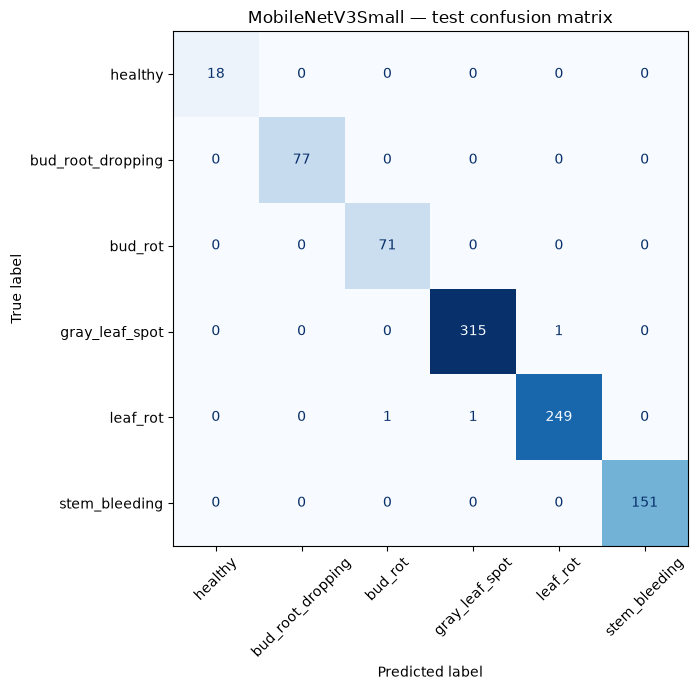

,class,precision,recall,f1,support
0,healthy,1.000000,1.000000,1.000000,18
1,bud_root_dropping,1.000000,1.000000,1.000000,77
2,bud_rot,0.986111,1.000000,0.993007,71
3,gray_leaf_spot,0.996835,0.996835,0.996835,316
4,leaf_rot,0.996000,0.992032,0.994012,251
5,stem_bleeding,1.000000,1.000000,1.000000,151



Evaluating MobileNetV3Large
111/111 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step


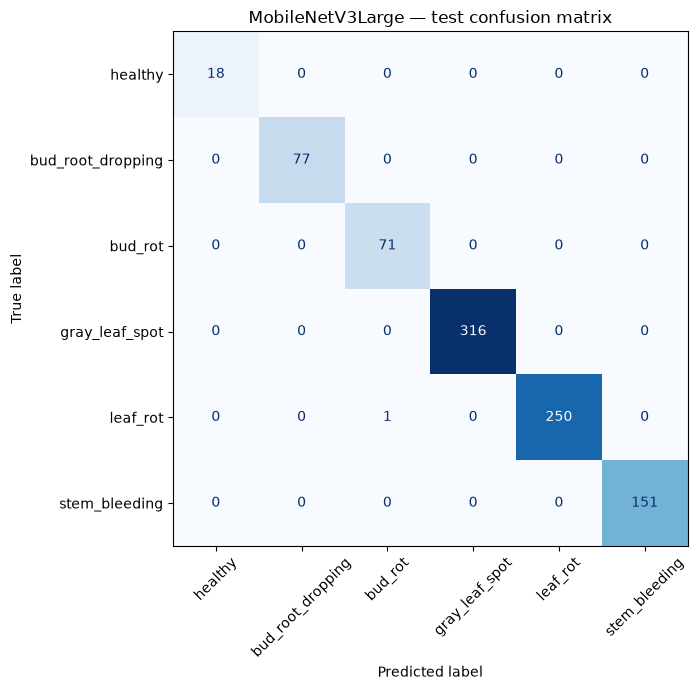

,class,precision,recall,f1,support
0,healthy,1.000000,1.000000,1.000000,18
1,bud_root_dropping,1.000000,1.000000,1.000000,77
2,bud_rot,0.986111,1.000000,0.993007,71
3,gray_leaf_spot,1.000000,1.000000,1.000000,316
4,leaf_rot,1.000000,0.996016,0.998004,251
5,stem_bleeding,1.000000,1.000000,1.000000,151



Evaluating ConvNeXtTiny
111/111 ━━━━━━━━━━━━━━━━━━━━ 332s 3s/step


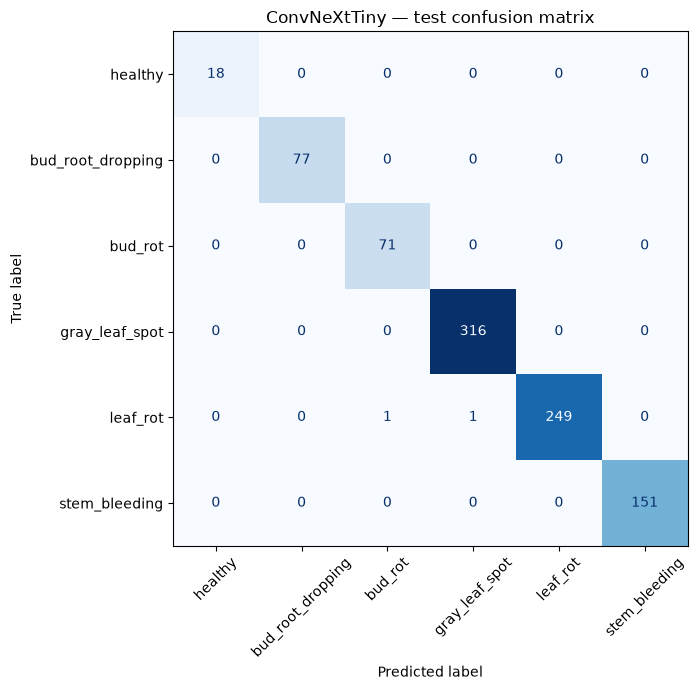

,class,precision,recall,f1,support
0,healthy,1.000000,1.000000,1.000000,18
1,bud_root_dropping,1.000000,1.000000,1.000000,77
2,bud_rot,0.986111,1.000000,0.993007,71
3,gray_leaf_spot,0.996845,1.000000,0.998420,316
4,leaf_rot,1.000000,0.992032,0.996000,251
5,stem_bleeding,1.000000,1.000000,1.000000,151


,architecture,test_accuracy,macro_precision,macro_recall,macro_f1,healthy_recall,healthy_f1
1,MobileNetV3Large,0.998869,0.997685,0.999336,0.998502,1.0,1.0
2,ConvNeXtTiny,0.997738,0.997159,0.998672,0.997905,1.0,1.0
0,MobileNetV3Small,0.996606,0.996491,0.998145,0.997309,1.0,1.0


In [9]:
def evaluate_architecture(architecture):
    model_path = MODEL_ROOT / architecture / "best_model.keras"
    if not model_path.exists():
        raise FileNotFoundError(f"Train {architecture} first: {model_path}")

    model = tf.keras.models.load_model(model_path)
    y_true = test_df["class_name"].map(class_to_index).values
    probs = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(probs, axis=1)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(len(CLASS_NAMES)), zero_division=0
    )
    report = pd.DataFrame({
        "class": CLASS_NAMES,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
    })

    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    summary = {
        "architecture": architecture,
        "test_accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "healthy_recall": float(recall[CLASS_NAMES.index("healthy")]),
        "healthy_f1": float(f1[CLASS_NAMES.index("healthy")]),
    }

    arch_dir = MODEL_ROOT / architecture
    report.to_csv(arch_dir / "per_class_test_metrics.csv", index=False)
    with open(arch_dir / "test_summary.json", "w") as f:
        json.dump(summary, f, indent=2)

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False
    )
    ax.set_title(f"{architecture} — test confusion matrix")
    plt.tight_layout()
    plt.show()

    display(report)
    del model
    tf.keras.backend.clear_session()
    return summary

# Automatically evaluate every model that completed training.
completed_architectures = [
    architecture for architecture in ARCHITECTURES
    if (MODEL_ROOT / architecture / "best_model.keras").exists()
]

if completed_architectures:
    evaluation_summaries = []
    for architecture in completed_architectures:
        print(f"\nEvaluating {architecture}")
        evaluation_summaries.append(evaluate_architecture(architecture))
    display(pd.DataFrame(evaluation_summaries).sort_values("macro_f1", ascending=False))
else:
    print("No completed models yet. Run section 8 first.")

## 10. Export TFLite for completed models
TFLite conversion is attempted independently for each trained model. ConvNeXtTiny may produce a larger file and may be slower on edge devices.

In [10]:
def export_tflite(architecture):
    model_path = MODEL_ROOT / architecture / "best_model.keras"
    if not model_path.exists():
        raise FileNotFoundError(model_path)

    model = tf.keras.models.load_model(model_path)
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_bytes = converter.convert()

    output_path = MODEL_ROOT / architecture / f"{architecture.lower()}_cococare.tflite"
    output_path.write_bytes(tflite_bytes)

    size_mb = output_path.stat().st_size / (1024 ** 2)
    print(architecture, "TFLite size:", round(size_mb, 2), "MB")
    del model
    tf.keras.backend.clear_session()
    return str(output_path), size_mb

# Example:
# export_tflite("MobileNetV3Small")

## 11. Build the architecture comparison table

In [11]:
# This reads test_summary.json and training_progress.csv for models already completed.
comparison_rows = []

for architecture in ARCHITECTURES:
    arch_dir = MODEL_ROOT / architecture
    summary_file = arch_dir / "test_summary.json"
    training_file = RESULT_ROOT / "training_progress.csv"

    if summary_file.exists():
        row = json.loads(summary_file.read_text())
        row["parameters"] = None
        if training_file.exists():
            progress = pd.read_csv(training_file)
            match = progress[progress.architecture == architecture]
            if len(match) and "parameters" in match:
                row["parameters"] = match.iloc[-1]["parameters"]
                row["training_seconds"] = match.iloc[-1].get("total_training_seconds")
        comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows)
if len(comparison):
    display(comparison.sort_values("macro_f1", ascending=False))
    comparison.to_csv(RESULT_ROOT / "architecture_comparison.csv", index=False)
else:
    print("No evaluated models yet. Train and evaluate models first.")

,architecture,test_accuracy,macro_precision,macro_recall,macro_f1,healthy_recall,healthy_f1,parameters,training_seconds
1,MobileNetV3Large,0.998869,0.997685,0.999336,0.998502,1.0,1.0,3002118.0,1471.184186
2,ConvNeXtTiny,0.997738,0.997159,0.998672,0.997905,1.0,1.0,27824742.0,26709.202204
0,MobileNetV3Small,0.996606,0.996491,0.998145,0.997309,1.0,1.0,942582.0,818.508368


## 12. Interpretation checklist

When comparing the four architectures, consider:

- **Macro-F1:** gives each class equal weight and is useful with class imbalance.
- **Healthy recall:** how many truly healthy test images are correctly recognized.
- **Healthy precision:** how often a Healthy prediction is actually healthy.
- **Per-disease recall:** whether any disease class is being missed.
- **Confusion matrix:** especially Healthy ↔ disease errors.
- **Model size and inference latency:** important for CocoCare deployment.
- **Generalization:** a random image split is not enough if images from the same tree, farm or capture session can occur in multiple splits.

### Limitations of this experiment
The healthy class currently has relatively few images compared with the disease classes. Class weighting does not create new visual diversity. A model may still overfit the healthy class. Collect more independently verified healthy coconut leaf images before making strong claims.

Do not select a model based on test accuracy alone. If you tune thresholds or make architecture decisions based on test results, obtain a new untouched test set for final reporting.

E0000 00:00:1794038306.624515    6719 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


NameError: name 'test_ds' is not defined